In [1]:
!pip install mne scikit-learn matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 45.4 MB/s eta 0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from mne.io import concatenate_raws, read_raw_edf

In [6]:
subject = 1
runs= [4,8,12] # runs where person imagines opening/closing the left or right

files = eegbci.load_data(subject, runs, update_path=True)
raw = concatenate_raws([read_raw_edf(f, preload=True) for f in files])
eegbci.standardize(raw)
raw.set_montage("standard_1005")

Using default location ~/mne_data for EEGBCI...
Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Extracting EDF parameters from /root/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R04.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Extracting EDF parameters from /root/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R08.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Extracting EDF parameters from /root/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R12.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...


/tmp/ipykernel_2596/2660928399.py:7: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage("standard_1005")


<RawEDF | S001R04.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>

<Info | 9 non-empty values
 bads: []
 ch_names: FC5, FC3, FC1, FCz, FC2, FC4, FC6, C5, C3, C1, Cz, C2, C4, C6, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>
Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


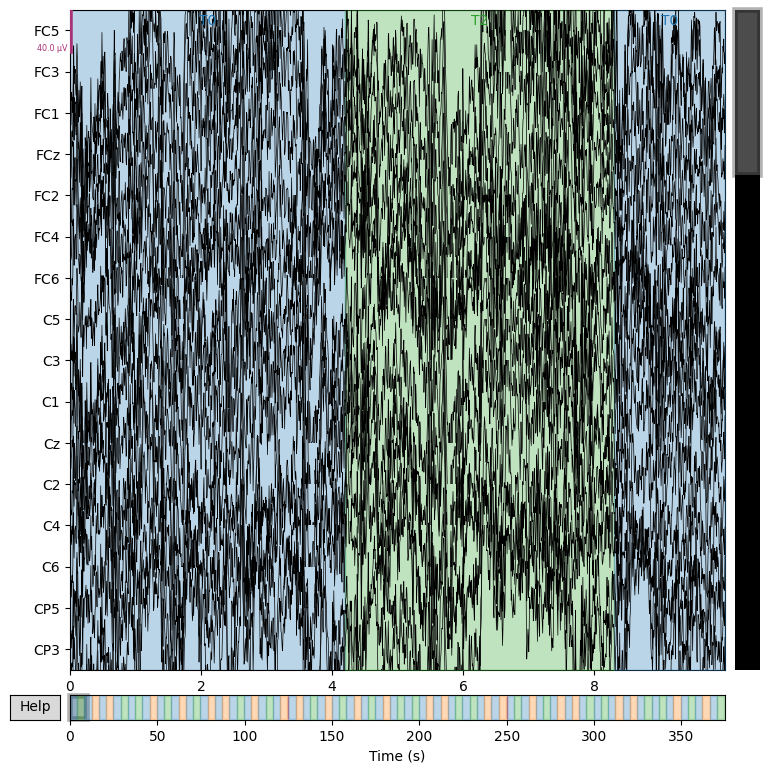

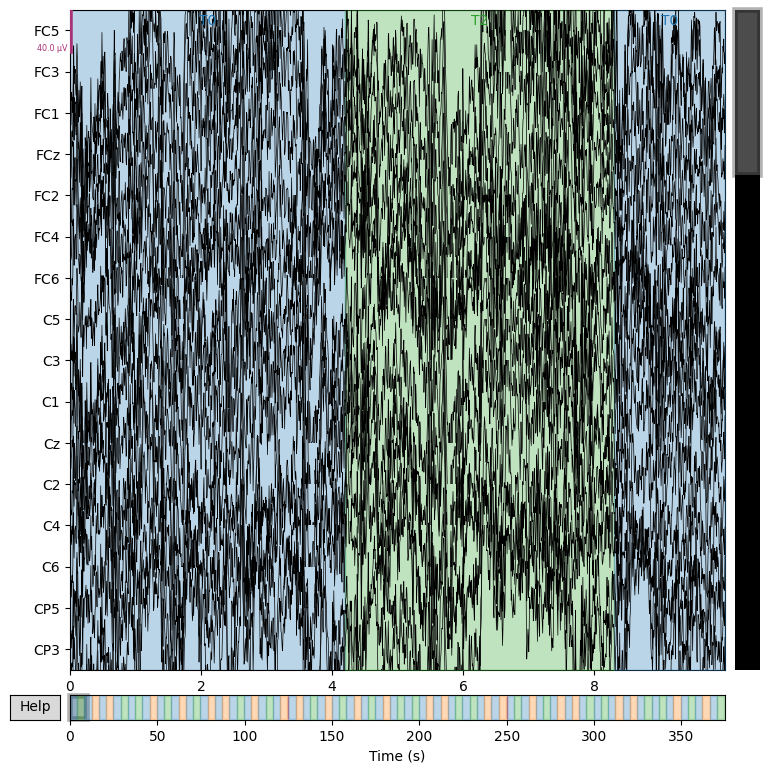

In [7]:
print(raw.info)
raw.plot(duration=10, n_channels=16)

In [8]:
print(raw.annotations.description[:10])

['T0' 'T2' 'T0' 'T1' 'T0' 'T1' 'T0' 'T2' 'T0' 'T2']


In [10]:
raw_before = raw.copy()
raw.filter(8., 30., fir_design="firwin", skip_by_annotation="edge")

Filtering raw data in 3 contiguous segments
Setting up band-pass filter from 8 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 265 samples (1.656 s)



<RawEDF | S001R04.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


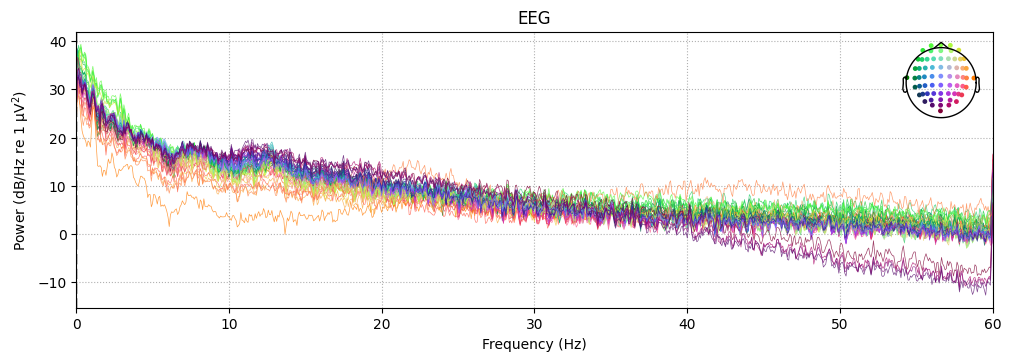

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


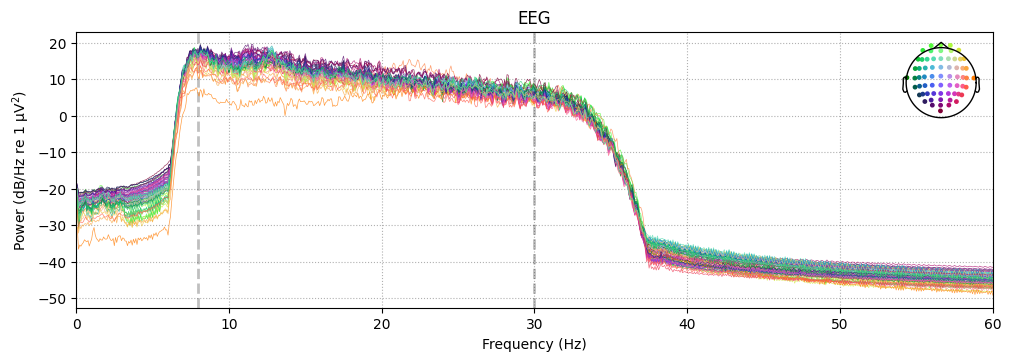

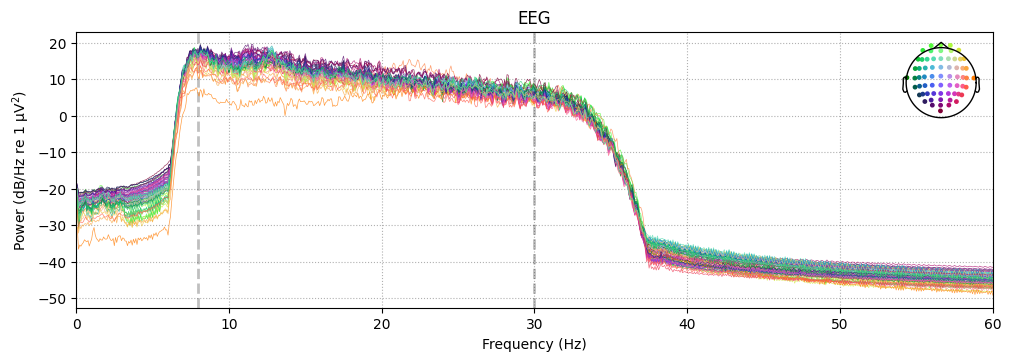

In [11]:
raw_before.compute_psd(fmax=60) .plot()
raw.compute_psd(fmax=60).plot()

raw_before.plot(duration=10, n_channels=8)
raw.plot(duration=10, n_channels=8);

In [13]:
events, _ = mne.events_from_annotations(raw, event_id={"T1":1, "T2":2})
event_id = {"left": 1, "right" :2}
picks = mne.pick_types(raw.info, eeg=True, exclude="bads")

epochs = mne.Epochs(raw, events, event_id, tmin=-1.0, tmax=4.0,
                    baseline=None, picks=picks, preload=True)
print(epochs)

Used Annotations descriptions: ['T1', 'T2']
Not setting metadata
45 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 45 events and 801 original time points ...
0 bad epochs dropped
<Epochs | 45 events (all good), -1 – 4 s (baseline off), ~17.7 MiB, data loaded,
 'left': 23
 'right': 22>


In [14]:
print("Left trials: ", len(epochs["left"]))
print("Right trials: ", len(epochs["right"]))

Left trials:  23
Right trials:  22


One epoch runs from 1s before the cue to 4s afterwards. Which give a short baseline and the imagery period. **Very few trials though**

    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows


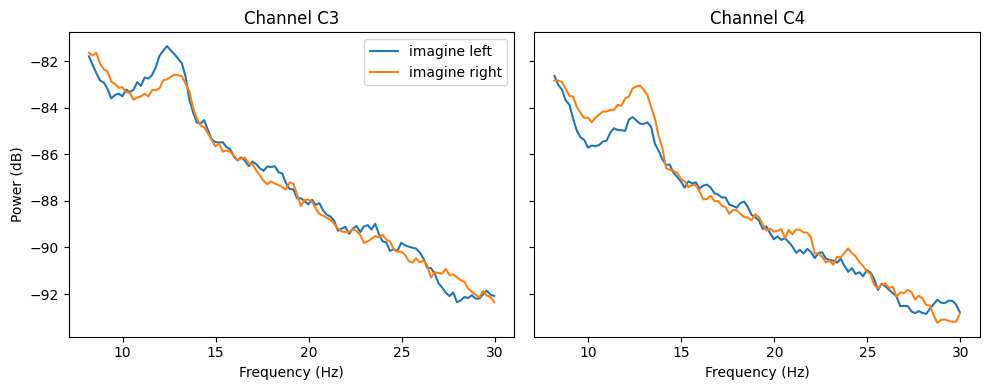

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)

for ax, ch in zip(axes, ["C3", "C4"]):
  for cond in ["left", "right"]:
    psd= epochs[cond].compute_psd(fmin=8, fmax=30, picks=[ch])
    data, freqs = psd.get_data (return_freqs=True)
    ax.plot(freqs, 10 * np.log10(data.mean(axis=0)[0]), label=f"imagine {cond}")
  ax.set_title(f"Channel {ch}")
  ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (dB)")
axes[0]. legend()
plt.tight_layout()
plt.savefig("results_figure.png", dpi=200)
plt.show()

Need more than one channel to make topography for eeg. Disabling interactivity.
Need more than one channel to make topography for eeg. Disabling interactivity.
Need more than one channel to make topography for eeg. Disabling interactivity.
Need more than one channel to make topography for eeg. Disabling interactivity.


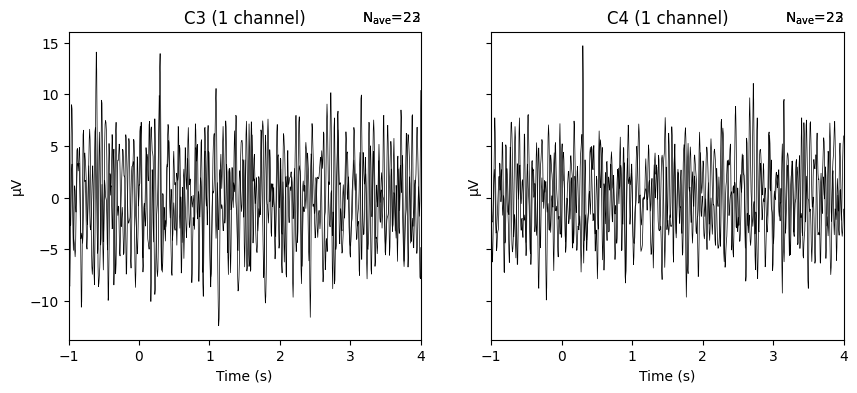

In [19]:
fig, axes = plt.subplots(1,2, figsize=(10,4), sharey=True)
for ax, ch in zip(axes, ["C3", "C4"]):
  for cond in ["left", "right"]:
    epochs[cond].average(picks=[ch]).plot(axes=ax, show=False, titles=ch)
plt.show()

This shows that:

*   C3 sits over the left motor cortex, and C4 sits over the right motor cortex

*   Imagining a left-hand movement should reduce mu/beta power over the right side (C4) and imagining a right-hand movement should reduce mu/beta power over the left side (C3) i.e: event-related desynchronisation (ERD)

*   The averaged signal might look flat, because ERD is not time-locked to the cue, so the averaging cancels it out. The power spectrum shows is better







In [22]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline


epochs_train = epochs.copy().crop(tmin=1.0, tmax=2.0)
x= epochs_train.get_data()
y= epochs_train.events[:,-1] -1


In [25]:
clf = Pipeline([
    ("CSP", CSP(n_components=4, reg=None, log=True, norm_trace=False)),
    ("LDA", LinearDiscriminantAnalysis()),
    ])

cv= ShuffleSplit(10, test_size=0.2, random_state=42)
scores = cross_val_score(clf, x, y, cv=cv)

print(f"Accuracy: {scores.mean():.2f} +- {scores.std():.2f}")
print(f"Chance level: {max(np.mean(y), 1 - np.mean(y)):.2f}")

Computing rank from data with rank=None
    Using tolerance 0.00014 (2.2e-16 eps * 64 dim * 9.8e+09  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 0.00014 (2.2e-16 eps * 64 dim * 9.5e+09  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 0.00014 (2.2e-16 eps * 64 dim * 9.9e+09  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMP

CSP: find spatial filters that maximinse the difference in variance between left and right. Variance here is a proxy for band power

LDA: a simple linear classifier that draws a straight boundary between the two classes

Cross validation: with so few trials, one train/ test split could be lucky or unlucky. Repeating gives a more accurate and honest estimate.



Analysis of Project:

Aim: classify left vs right imagined hand movement from EEG

Method: dataset, filter, epochs, CSP + LDA, cross-validation

Result: Accuracy: 0.66 +- 0.17, Chance Level: 0.51 Figure (Below)

Limitations: One subject only, small sample, offline analysis, no real-time use


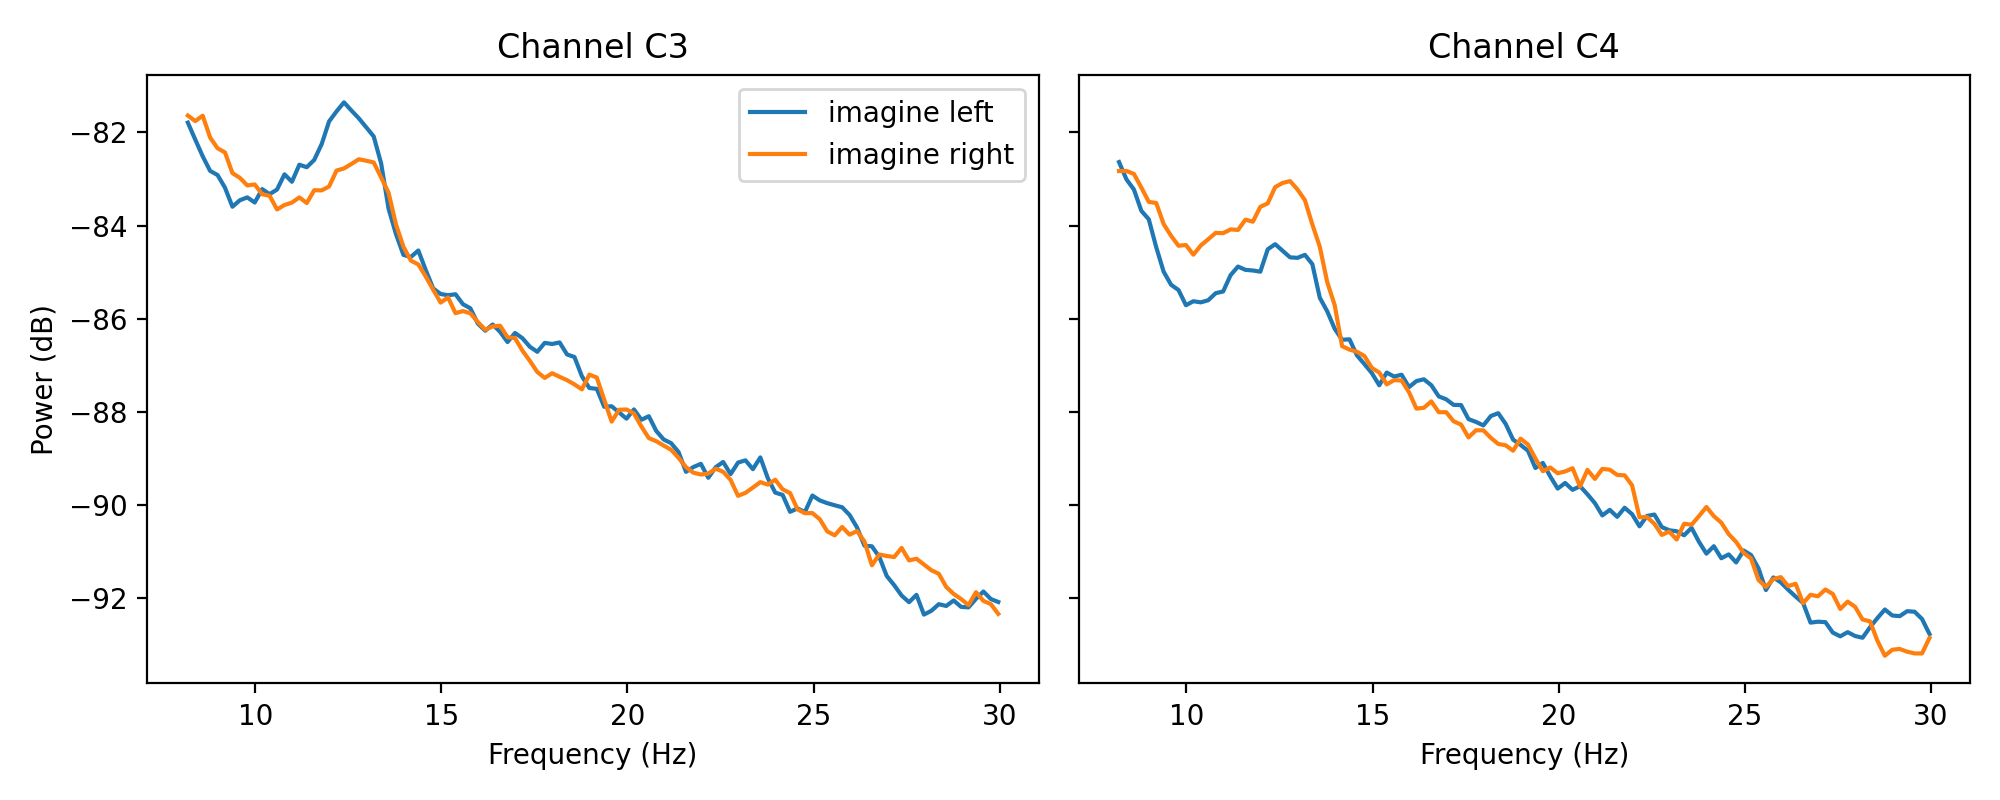

In [27]:
from IPython.display import Image
Image("results_figure.png")